[1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1]
[0 0 0 0 0 0 0 1 0 0 1 1 0 0 0]


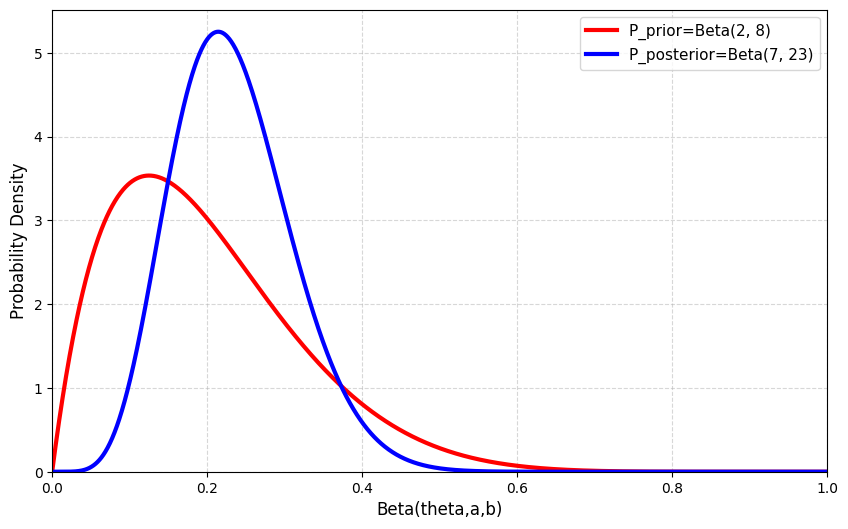

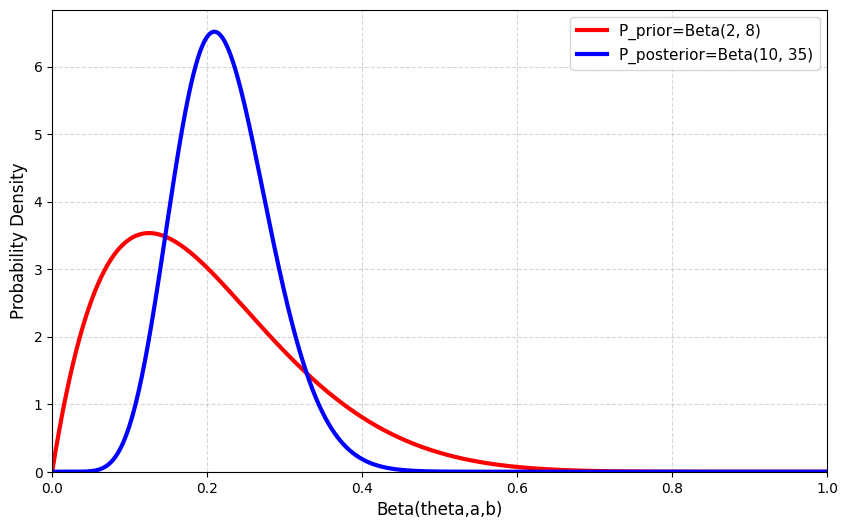

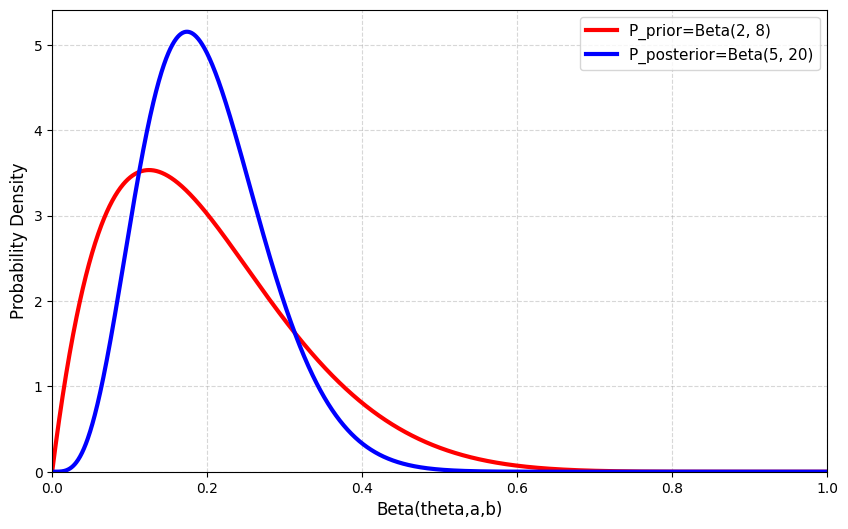

In [ ]:
# cod adaptat din ex. 1 din tema 6

import numpy as np
import pymc as pm

import arviz as az
import matplotlib.pyplot as plt
import scipy.stats

obs1 = np.array(([1]*5)+([0]*15))[np.random.permutation(20)]
print(obs1)

obs2 = np.array(([1]*3)+([0]*12))[np.random.permutation(15)]
print(obs2)

def plot(alpha, beta, obs):
    x = np.linspace(0, 1, 2000)
    a = np.count_nonzero(obs)
    b = obs.size - a

    shapes = [
        {"a": alpha, "b": beta, "color": "red", "label": f"P_prior=Beta({alpha}, {beta})"},
        {"a": alpha+a, "b": beta+b, "color": "blue", "label": f"P_posterior=Beta({alpha+a}, {beta+b})"},
    ]

    plt.figure(figsize=(10, 6))
    ys = []

    for shape in shapes:
        a, b = shape["a"], shape["b"]
        y = scipy.stats.beta.pdf(x, a, b)
        ys.append(y)
        # print(shape["label"])
        plt.plot(x, y, linewidth=3, color=shape["color"], label=shape["label"])

    plt.xlabel("Beta(theta,alpha,beta)", fontsize=12)
    plt.ylabel("Probability Density", fontsize=12)
    plt.xlim(0, 1)
    plt.ylim(bottom=0)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=11, frameon=True)
    plt.show()

# a)
plot(alpha = 2, beta = 8, obs = obs1)

# b)
obsb = np.array([0]*(obs1.size + obs2.size))
for i in range(obs1.size): obsb[i]=obs1[i]
for i in range(obs2.size): obsb[i+obs1.size]=obs1[i]
plot(alpha = 2, beta = 8, obs = obsb)

# c)
plot(alpha = 2, beta = 8, obs = obs2)


# modul (theta cu Beta(theta, alpha, beta) maxim pentru distributia Beta(theta, alpha, beta) este (alpha-1)/(alpha+beta-2)
# pentru P_prior=Beta(2,8), modul este 1/8=0.125 (pdf-ul rosu)
# pentru P_posterior_a=Beta(7,23), modul este 6/28=0.214... (pdf-ul albastru din primul grafic)
# pentru P_posterior_b=Beta(10,35), modul este 9/43=0.2093... (pdf-ul albastru din al doilea grafic)
# pentru P_posterior_c=Beta(5,20), modul este 4/23=0.1739... (pdf-ul albastru din al treilea grafic)